Q21. Train a KNN Classifier on the Iris dataset and print accuracy.

In [35]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [ ]:
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(), KNeighborsClassifier(n_neighbors=5)
)
model.fit(X_train, y_train)

print("Accuracy:", accuracy_score(y_test, model.predict(X_test)))

Accuracy: 0.9333333333333333


Explanation: KNN classifies each flower using its five nearest neighbors. Feature scaling ensures that measurements with larger numerical ranges do not dominate distance calculations.

Q22. Train a KNN Regressor on synthetic data and evaluate using MSE.

In [ ]:
X, y = make_regression(
    n_samples=500, n_features=4, noise=15, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    StandardScaler(), KNeighborsRegressor(n_neighbors=5)
)
model.fit(X_train, y_train)

print("MSE:", mean_squared_error(y_test, model.predict(X_test)))

MSE: 498.1858173132947


Explanation: The regressor predicts numerical values by averaging nearby training targets. MSE measures the average squared prediction error.

Q23. Compare Euclidean and Manhattan distance metrics in KNN.

In [ ]:
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

for metric in ["euclidean", "manhattan"]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5, metric=metric)
    )
    model.fit(X_train, y_train)
    print(metric, "accuracy:",
          accuracy_score(y_test, model.predict(X_test)))

euclidean accuracy: 0.9333333333333333
manhattan accuracy: 0.9333333333333333


Explanation: Both models use the same data split and value of K. The comparison shows how the choice of distance metric affects predictions.

Q24. Train KNN with different values of K and visualize decision boundaries.

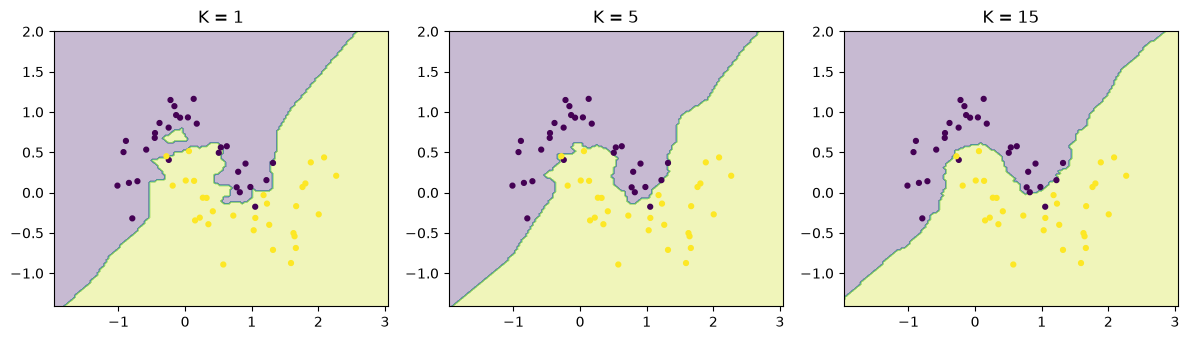

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for ax, k in zip(axes, [1, 5, 15]):
    model = make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=k)
    )
    model.fit(X_train, y_train)

    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 150),
        np.linspace(X[:, 1].min()-0.5, X[:, 1].max()+0.5, 150)
    )
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=12)
    ax.set_title(f"K = {k}")

plt.tight_layout()
plt.show()

Explanation: A small K creates a more sensitive boundary, while a larger K usually creates a smoother boundary.

Q25. Apply feature scaling before KNN and compare with unscaled data.

In [10]:
from sklearn.datasets import load_wine

X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Unscaled": KNeighborsClassifier(n_neighbors=5),
    "Scaled": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "accuracy:",
          accuracy_score(y_test, model.predict(X_test)))

Unscaled accuracy: 0.8055555555555556
Scaled accuracy: 0.9722222222222222


Explanation: Wine features have different numerical scales. The scaled model gives each feature a more comparable influence on distance calculations.

Q26. Train PCA on synthetic data and print explained variance ratios.

In [11]:
from sklearn.datasets import make_classification
from sklearn.decomposition import PCA

X, _ = make_classification(
    n_samples=300, n_features=5, n_informative=3,
    n_redundant=1, random_state=42
)

X_scaled = StandardScaler().fit_transform(X)
pca = PCA()
pca.fit(X_scaled)

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)
print("Total variance explained:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[4.63662668e-01 2.36627987e-01 1.89761992e-01 1.09947353e-01
 4.42608912e-17]
Total variance explained:
1.0


Explanation: Each ratio indicates the fraction of total variance explained by a principal component. Together, all components explain 100% of the variance in the centered data, apart from numerical rounding.

Q27. Apply PCA before KNN and compare accuracy with and without PCA.

In [ ]:
X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Without PCA": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "With PCA": make_pipeline(
        StandardScaler(), PCA(n_components=0.95),
        KNeighborsClassifier(n_neighbors=5)
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "accuracy:",
          accuracy_score(y_test, model.predict(X_test)))

Without PCA accuracy: 0.9722222222222222
With PCA accuracy: 0.9722222222222222


Explanation: PCA retains enough components to explain approximately 95% of the training variance. Comparing test accuracy shows whether dimensionality reduction helps this KNN model.

Q28. Perform hyperparameter tuning on KNN using GridSearchCV.

In [13]:
from sklearn.model_selection import GridSearchCV

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
grid = GridSearchCV(
    pipe,
    {
        "kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11],
        "kneighborsclassifier__weights": ["uniform", "distance"],
        "kneighborsclassifier__metric": ["euclidean", "manhattan"]
    },
    cv=5, scoring="accuracy"
)

grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Test accuracy:", grid.score(X_test, y_test))

Best parameters: {'kneighborsclassifier__metric': 'euclidean', 'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'uniform'}
Test accuracy: 0.9333333333333333


Explanation: GridSearchCV evaluates different K values, weighting methods, and distance metrics using five-fold cross-validation.

Q29. Train KNN and count misclassified samples.

In [ ]:
data = load_iris()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(), KNeighborsClassifier(n_neighbors=5)
)
model.fit(X_train, y_train)
pred = model.predict(X_test)

wrong = np.where(pred != y_test)[0]
print("Misclassified samples:", len(wrong))
print("Misclassified test indices:", wrong)

Misclassified samples: 2
Misclassified test indices: [19 23]


Explanation: The program identifies test observations whose predicted labels differ from their true labels.

Q30. Train PCA and visualize cumulative explained variance.

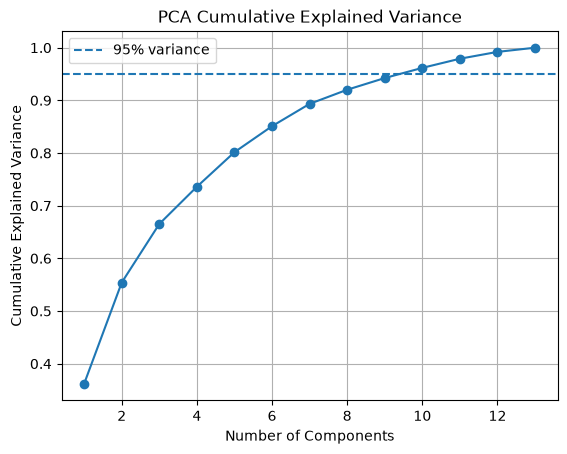

Components for 95% variance: 10


In [ ]:
X, _ = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

pca = PCA().fit(X_scaled)
cumulative = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

print("Components for 95% variance:",
      np.argmax(cumulative >= 0.95) + 1)

Explanation: The plot shows how much total variance is retained as components are added.

Q31. Compare uniform and distance-based KNN weights.

In [ ]:
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

for weights in ["uniform", "distance"]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5, weights=weights)
    )
    model.fit(X_train, y_train)
    print(weights, "accuracy:",
          accuracy_score(y_test, model.predict(X_test)))

uniform accuracy: 0.9333333333333333
distance accuracy: 0.9666666666666667


Explanation: Uniform weighting gives every neighbor equal importance. Distance weighting gives closer neighbors more influence.

Q32. Analyze the effect of different K values on KNN regression.

In [18]:
from sklearn.datasets import make_regression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

X, y = make_regression(
    n_samples=500, n_features=4, noise=15, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for k in [1, 3, 5, 10, 20]:
    model = make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=k)
    )
    model.fit(X_train, y_train)
    print(f"K={k}, MSE={mean_squared_error(y_test, model.predict(X_test)):.4f}")

K=1, MSE=812.1624
K=3, MSE=547.9293
K=5, MSE=498.1858
K=10, MSE=496.6554
K=20, MSE=593.9453


Explanation: A small K can overfit, while a large K can oversmooth predictions. Compare test MSE to see how K affects performance.

Q33. Implement KNN Imputation for missing values.

In [19]:
from sklearn.impute import KNNImputer

X = np.array([
    [20, 20000],
    [25, 30000],
    [30, np.nan],
    [35, 50000],
    [np.nan, 60000]
], dtype=float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

imputer = KNNImputer(n_neighbors=2)
X_imputed_scaled = imputer.fit_transform(X_scaled)
X_imputed = scaler.inverse_transform(X_imputed_scaled)

print("Original data:\n", X)
print("Imputed data:\n", X_imputed)

Original data:
 [[2.0e+01 2.0e+04]
 [2.5e+01 3.0e+04]
 [3.0e+01     nan]
 [3.5e+01 5.0e+04]
 [    nan 6.0e+04]]
Imputed data:
 [[2.0e+01 2.0e+04]
 [2.5e+01 3.0e+04]
 [3.0e+01 4.0e+04]
 [3.5e+01 5.0e+04]
 [3.0e+01 6.0e+04]]


Explanation: KNN Imputer estimates missing values using similar rows. Scaling helps prevent the income feature from dominating the age feature.

Q34. Visualize data projected onto the first two principal components.

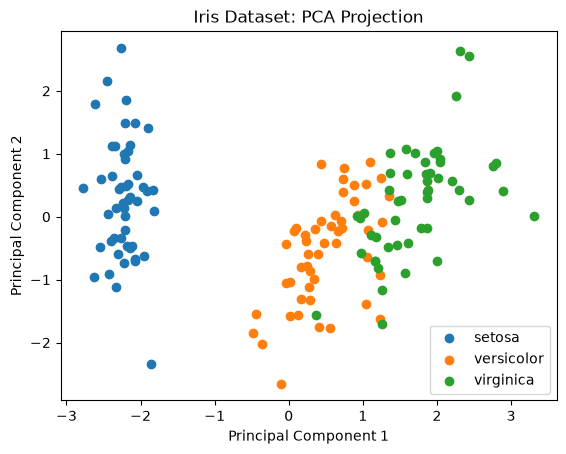

In [ ]:
data = load_iris()
X, y = data.data, data.target

X_scaled = StandardScaler().fit_transform(X)
X_pca = PCA(n_components=2).fit_transform(X_scaled)

for class_id, name in enumerate(data.target_names):
    plt.scatter(
        X_pca[y == class_id, 0],
        X_pca[y == class_id, 1],
        label=name
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset: PCA Projection")
plt.legend()
plt.show()

Explanation: The four original Iris features are reduced to two principal components, making the data easier to visualize.

Q35. Compare KD Tree and Ball Tree algorithms in KNN.

In [21]:
import time

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

for algorithm in ["kd_tree", "ball_tree"]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5, algorithm=algorithm)
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    elapsed = time.perf_counter() - start

    print(algorithm)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Fit + prediction time (seconds):", round(elapsed, 6))

kd_tree
Accuracy: 0.9333333333333333
Fit + prediction time (seconds): 0.005993
ball_tree
Accuracy: 0.9333333333333333
Fit + prediction time (seconds): 0.004466


Explanation: The program compares accuracy and combined fit-and-prediction time. Small datasets such as Iris are not large enough to establish which algorithm will be faster on other datasets.

Q36. Train PCA on high-dimensional data and create a Scree plot.

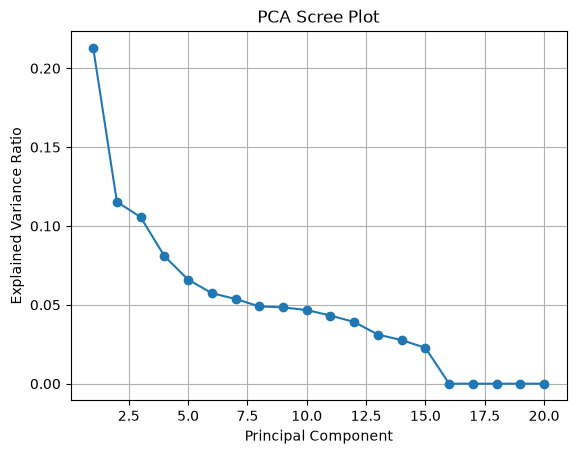

In [ ]:
X, _ = make_classification(
    n_samples=300, n_features=20, n_informative=10,
    n_redundant=5, random_state=42
)

X_scaled = StandardScaler().fit_transform(X)
pca = PCA().fit(X_scaled)

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_, marker="o"
)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.grid(True)
plt.show()

Explanation: The Scree plot shows the variance explained by each component. A point where the curve starts flattening can help identify a reasonable number of components.

Q37. Evaluate KNN using Precision, Recall, and F1-score.

In [23]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import classification_report

data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(), KNeighborsClassifier(n_neighbors=5)
)
model.fit(X_train, y_train)

print(classification_report(
    y_test, model.predict(X_test), target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Explanation: The classification report provides precision, recall, and F1-score for both classes.

Q38. Analyze how the number of PCA components affects KNN accuracy.

In [ ]:
X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

for n in [2, 5, 8, 11, 13]:
    model = make_pipeline(
        StandardScaler(),
        PCA(n_components=n),
        KNeighborsClassifier(n_neighbors=5)
    )
    model.fit(X_train, y_train)
    print(f"Components: {n}, Accuracy: "
          f"{accuracy_score(y_test, model.predict(X_test)):.4f}")

Components: 2, Accuracy: 0.9167
Components: 5, Accuracy: 1.0000
Components: 8, Accuracy: 0.9722
Components: 11, Accuracy: 0.9722
Components: 13, Accuracy: 0.9722


Explanation: This experiment measures how retaining different numbers of components affects classification. All preprocessing is fitted on the training data through the pipeline.

Q39. Compare different leaf_size values in KNN.

In [ ]:
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

for leaf in [10, 20, 30, 40, 50]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=5, algorithm="kd_tree", leaf_size=leaf
        )
    )
    model.fit(X_train, y_train)
    print(f"Leaf size: {leaf}, Accuracy: "
          f"{accuracy_score(y_test, model.predict(X_test)):.4f}")

Leaf size: 10, Accuracy: 0.9333
Leaf size: 20, Accuracy: 0.9333
Leaf size: 30, Accuracy: 0.9333
Leaf size: 40, Accuracy: 0.9333
Leaf size: 50, Accuracy: 0.9333


Explanation: leaf_size affects KD Tree construction and search efficiency. It usually does not change the mathematical neighbors or accuracy, except for possible numerical or tie-related differences.

Q40. Visualize data before and after PCA.

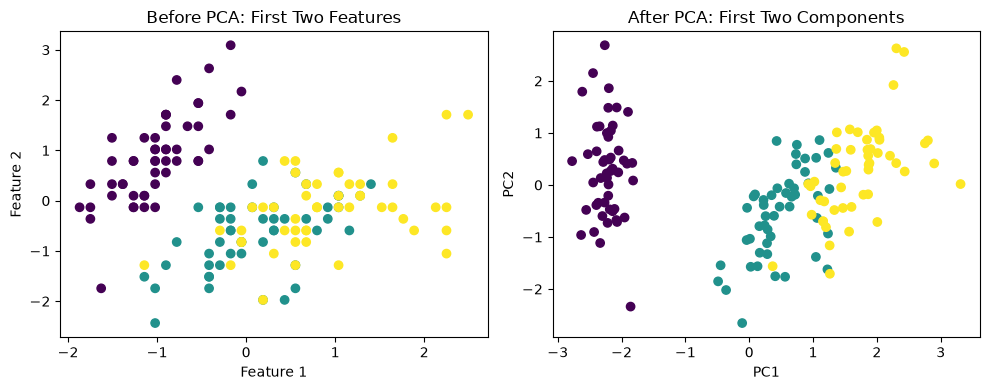

In [ ]:
data = load_iris()
X, y = data.data, data.target
X_scaled = StandardScaler().fit_transform(X)

X_pca = PCA(n_components=2).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], c=y)
axes[0].set_title("Before PCA: First Two Features")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y)
axes[1].set_title("After PCA: First Two Components")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

Explanation: The first plot shows two original features, while the second shows the data projected onto the first two principal components. PCA can reveal patterns that are not obvious in the original feature pair.

Q41. Train KNN on the Wine dataset and print the classification report.

In [ ]:
data = load_wine()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(), KNeighborsClassifier(n_neighbors=5)
)
model.fit(X_train, y_train)

print(classification_report(
    y_test, model.predict(X_test), target_names=data.target_names
))

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      0.93      0.96        14
     class_2       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



Explanation: The model classifies wine into one of three classes and reports precision, recall, F1-score, and support.

Q42. Compare distance metrics in KNN regression.

In [ ]:
X, y = make_regression(
    n_samples=500, n_features=4, noise=15, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for metric in ["euclidean", "manhattan"]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5, metric=metric)
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(metric, "MSE:", mean_squared_error(y_test, pred))

euclidean MSE: 498.1858173132947
manhattan MSE: 534.4094086219433


Q43. Evaluate KNN using ROC-AUC.

Explanation: Both distance metrics are compared using the same test set. Lower MSE indicates better regression performance for that split.

In [29]:
from sklearn.metrics import roc_auc_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(), KNeighborsClassifier(n_neighbors=5)
)
model.fit(X_train, y_train)

prob = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, prob))

ROC-AUC: 0.9788359788359788


Explanation: ROC-AUC evaluates how well the model ranks positive samples above negative samples across different classification thresholds.

Q44. Train PCA and visualize variance captured by each component.

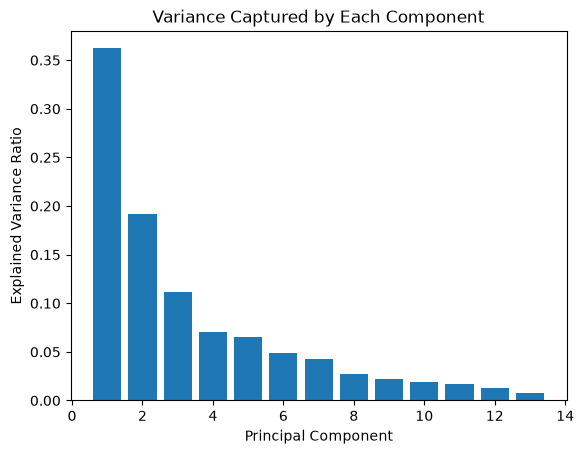

Variance ratios: [0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]


In [ ]:
X, _ = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

pca = PCA().fit(X_scaled)
variance = pca.explained_variance_ratio_

plt.bar(range(1, len(variance) + 1), variance)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Variance Captured by Each Component")
plt.show()

print("Variance ratios:", variance)

Explanation: The bar chart shows how much variance each principal component captures. The first components usually capture more variance than the later components.

Q45. Train KNN after feature selection and compare accuracy.

In [31]:
from sklearn.feature_selection import SelectKBest, f_classif

X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "All features": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "Selected features": make_pipeline(
        SelectKBest(score_func=f_classif, k=5),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "accuracy:",
          accuracy_score(y_test, model.predict(X_test)))

All features accuracy: 0.9722222222222222
Selected features accuracy: 0.9722222222222222


Explanation: SelectKBest selects five features based on their individual statistical relationship with the target. Putting feature selection inside the pipeline prevents it from learning from the test data.

Q46. Visualize PCA reconstruction error after reducing dimensions.

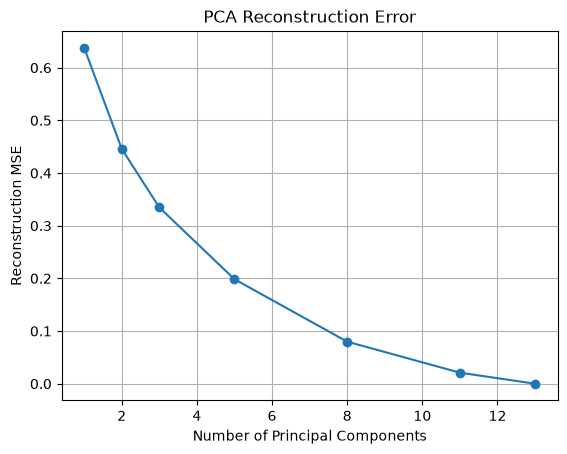

Components: 1, Reconstruction MSE: 0.638012
Components: 2, Reconstruction MSE: 0.445937
Components: 3, Reconstruction MSE: 0.334700
Components: 5, Reconstruction MSE: 0.198377
Components: 8, Reconstruction MSE: 0.079825
Components: 11, Reconstruction MSE: 0.020934
Components: 13, Reconstruction MSE: 0.000000


In [ ]:
X, _ = load_wine(return_X_y=True)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

components = [1, 2, 3, 5, 8, 11, 13]
errors = []

for n in components:
    pca = PCA(n_components=n)
    reduced = pca.fit_transform(X_scaled)
    reconstructed = pca.inverse_transform(reduced)
    errors.append(mean_squared_error(X_scaled, reconstructed))

plt.plot(components, errors, marker="o")
plt.xlabel("Number of Principal Components")
plt.ylabel("Reconstruction MSE")
plt.title("PCA Reconstruction Error")
plt.grid(True)
plt.show()

for n, error in zip(components, errors):
    print(f"Components: {n}, Reconstruction MSE: {error:.6f}")

Explanation: Reconstruction error measures how much information is lost when the data is reduced and reconstructed. It generally decreases as more components are retained.

Q47. Train KNN and visualize its decision boundary.

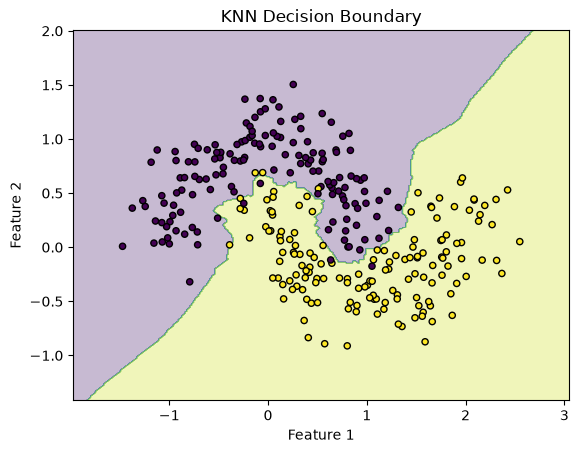

In [ ]:
X, y = make_moons(n_samples=300, noise=0.2, random_state=42)

model = make_pipeline(
    StandardScaler(), KNeighborsClassifier(n_neighbors=5)
)
model.fit(X, y)

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 300),
    np.linspace(X[:, 1].min()-0.5, X[:, 1].max()+0.5, 300)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k", s=20)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("KNN Decision Boundary")
plt.show()

Explanation: The synthetic dataset contains two nonlinear classes. The plot displays the regions in which KNN predicts each class.

Q48. Analyze the effect of different PCA component counts on explained variance.

Components: 1, Variance explained: 0.3620
Components: 2, Variance explained: 0.5541
Components: 3, Variance explained: 0.6653
Components: 5, Variance explained: 0.8016
Components: 8, Variance explained: 0.9202
Components: 11, Variance explained: 0.9791
Components: 13, Variance explained: 1.0000


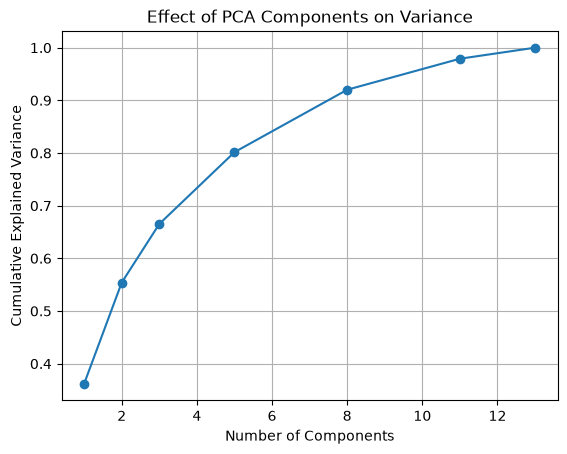

In [ ]:
X, _ = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

component_counts = [1, 2, 3, 5, 8, 11, 13]
variance = []

for n in component_counts:
    pca = PCA(n_components=n)
    pca.fit(X_scaled)
    variance.append(pca.explained_variance_ratio_.sum())

for n, v in zip(component_counts, variance):
    print(f"Components: {n}, Variance explained: {v:.4f}")

plt.plot(component_counts, variance, marker="o")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Effect of PCA Components on Variance")
plt.grid(True)
plt.show()

Explanation: Increasing the number of principal components generally increases the total variance retained. The goal is to retain enough useful information while reducing the number of features.